# Logistic Regression


We will load a real dataset **Pima Indians Diabetes** from Internet and train a model using **logistic regression** to predict the presence of diabetes (1) vs absence (0).

**Lab Objectives :**
1. Download the public data 
2. Prepare the features and the target variable
3. Train a logistic regression model and evaluate performance
4. Visualize the ROC / AUC curve
5. Interpreting the coefficients (odds ratios)
6. Make a prediction for a new example


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### 1) Download and explore the dataset
We read the CSV directly from GitHub (internet). The columns are numeric, with `Outcome` as the binary label.


In [2]:
# Pas d'accès à Internet ici, on utilise le même fichier en local (pima-indians-diabetes.csv, sans en-tête)
cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin',
        'BMI','DiabetesPedigreeFunction','Age','Outcome']
df = pd.read_csv('pima-indians-diabetes.csv', header=None, names=cols)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### 2) Split train/test, normalize, train
We use `StandardScaler` and then a `LogisticRegression` model from scikit-learn.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000, n_jobs=None)  # n_jobs ignoré selon version
clf.fit(X_train_scaled, y_train)

y_pred = clf.predict(X_test_scaled)
print('Accuracy:', accuracy_score(y_test, y_pred))
print('\nConfusion matrix:\n', confusion_matrix(y_test, y_pred))
print('\nClassification report:\n', classification_report(y_test, y_pred))


Accuracy: 0.734375

Confusion matrix:
 [[106  19]
 [ 32  35]]

Classification report:
               precision    recall  f1-score   support

           0       0.77      0.85      0.81       125
           1       0.65      0.52      0.58        67

    accuracy                           0.73       192
   macro avg       0.71      0.69      0.69       192
weighted avg       0.73      0.73      0.73       192



### 3) ROC curve and AUC


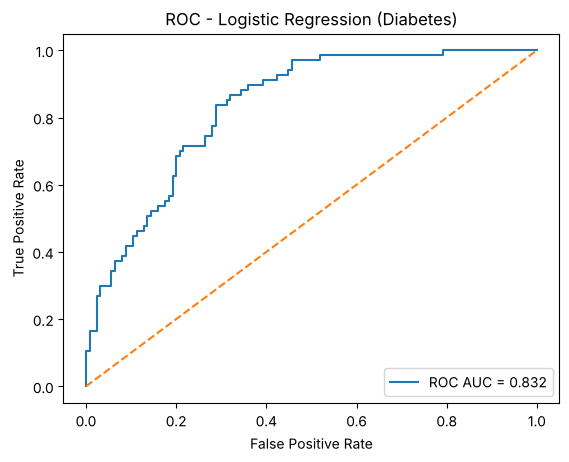

0.832

In [5]:
from sklearn.metrics import roc_curve, auc

y_proba = clf.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC - Logistic Regression (Diabetes)')
plt.legend(loc='lower right')
plt.show()
roc_auc


### 4) Interpretation of coefficients (odds ratios)
We can transform the coefficients into **odds ratios** with `exp(coef_)`.


In [6]:
coef = pd.Series(clf.coef_[0], index=X.columns).sort_values(ascending=False)
odds_ratio = np.exp(coef)
pd.DataFrame({'coefficient': coef, 'odds_ratio': odds_ratio})


,coefficient,odds_ratio
Glucose,1.111573,3.039136
BMI,0.727884,2.070695
Pregnancies,0.430638,1.538238
DiabetesPedigreeFunction,0.237857,1.268527
Age,0.154219,1.166746
SkinThickness,-0.007689,0.992341
Insulin,-0.079121,0.923928
BloodPressure,-0.204350,0.815177


### 5) Make a prediction for a new individual
We create a realistic example and produce the probability of diabetes.


In [7]:
nouvel_exemple = pd.DataFrame([
    {
        'Pregnancies': 2,
        'Glucose': 120,
        'BloodPressure': 70,
        'SkinThickness': 20,
        'Insulin': 79,
        'BMI': 28.5,
        'DiabetesPedigreeFunction': 0.45,
        'Age': 33
    }
])
nouvel_exemple_scaled = scaler.transform(nouvel_exemple)
proba = clf.predict_proba(nouvel_exemple_scaled)[0,1]
pred = clf.predict(nouvel_exemple_scaled)[0]
print('Probability of diabetes:', round(proba, 3))
print('Predicted class (0 = non, 1 = oui):', int(pred))


Probability of diabetes: 0.182
Predicted class (0 = non, 1 = oui): 0


## Activity


<ol>
    <li>Compute all classification metrics (recall, precision, F-measure, sensitivity, specificity, ... ), and plot the confusion matrix and the Recall/Precision curve. Interpret the results ?</li>
    <li>Change the dataset  by imputing the 0's (ex. BMI, Glucose) by the median then re-train.</li>
    <li>Use Cross-validation to report the final results.</li>
</ol>


In [8]:
# 1) toutes les métriques de classification
from sklearn.metrics import (precision_score, recall_score, f1_score, precision_recall_curve,
                             average_precision_score, ConfusionMatrixDisplay, roc_auc_score)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)
print("Accuracy           :", round(accuracy_score(y_test, y_pred), 4))
print("Precision          :", round(precision_score(y_test, y_pred), 4))
print("Recall/Sensibilité :", round(recall_score(y_test, y_pred), 4))
print("Spécificité        :", round(tn / (tn + fp), 4))
print("F1                 :", round(f1_score(y_test, y_pred), 4))
print("AUC                :", round(roc_auc, 4))

TN = 106  FP = 19  FN = 32  TP = 35
Accuracy           : 0.7344
Precision          : 0.6481
Recall/Sensibilité : 0.5224
Spécificité        : 0.848
F1                 : 0.5785
AUC                : 0.832


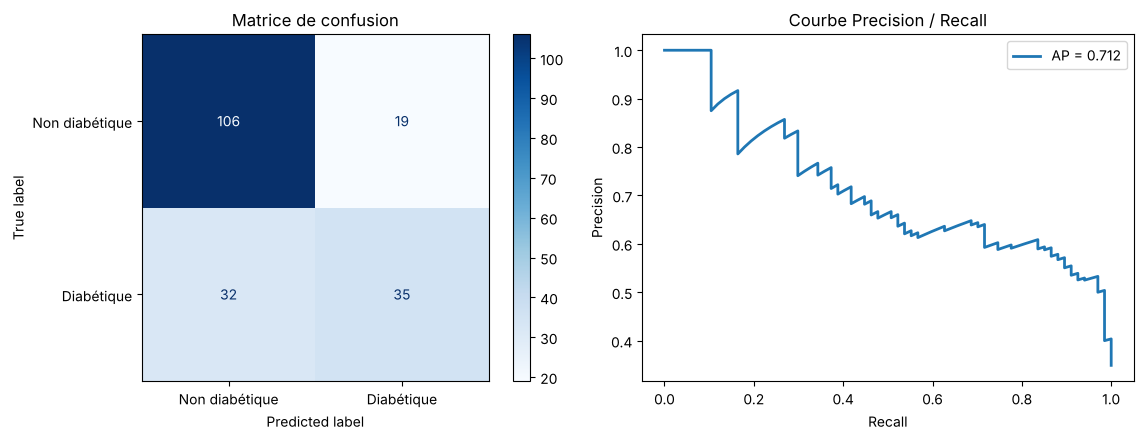

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Non diabétique', 'Diabétique'], ax=axes[0], cmap='Blues')
axes[0].set_title('Matrice de confusion')

prec, rec, seuils = precision_recall_curve(y_test, y_proba)
axes[1].plot(rec, prec, linewidth=2, label='AP = ' + str(round(average_precision_score(y_test, y_proba), 3)))
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Courbe Precision / Recall')
axes[1].legend()
plt.tight_layout()
plt.show()

**Interprétation :**

- L'accuracy est de 0.73, mais elle cache une différence entre les deux classes : la précision (0.65) et surtout le recall (0.52) pour la classe "diabétique" sont faibles. Le modèle ne détecte qu'environ la moitié des vrais diabétiques (35 sur 67) et fait 32 faux négatifs, alors que la spécificité est bien meilleure (0.85).
- En médecine, un faux négatif (patient malade non détecté) est plus grave qu'un faux positif, donc ce recall faible est un problème. On pourrait baisser le seuil de décision (0.5) pour augmenter le recall, au prix d'une baisse de la précision, ce qu'on voit sur la courbe Precision/Recall.
- L'AUC de 0.83 montre que le modèle classe quand même assez bien les patients : le problème vient surtout du seuil et des classes déséquilibrées (65% non diabétiques et 35% diabétiques).

In [10]:
# 2) imputation des 0 par la médiane puis ré-entraînement
cols_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("Nombre de 0 par colonne :")
print((df[cols_zero] == 0).sum())

df2 = df.copy()
df2[cols_zero] = df2[cols_zero].replace(0, np.nan)
df2[cols_zero] = df2[cols_zero].fillna(df2[cols_zero].median())     # médiane de chaque colonne
print()
print(df2[cols_zero].isnull().sum().sum(), "valeurs manquantes après imputation")

X2 = df2.drop('Outcome', axis=1)
y2 = df2['Outcome']
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=42, stratify=y2)

scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

clf2 = LogisticRegression(max_iter=1000)
clf2.fit(X2_train_s, y2_train)
y2_pred = clf2.predict(X2_test_s)
y2_proba = clf2.predict_proba(X2_test_s)[:, 1]

tn2, fp2, fn2, tp2 = confusion_matrix(y2_test, y2_pred).ravel()
avant = [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred),
         tn / (tn + fp), f1_score(y_test, y_pred), roc_auc]
apres = [accuracy_score(y2_test, y2_pred), precision_score(y2_test, y2_pred), recall_score(y2_test, y2_pred),
         tn2 / (tn2 + fp2), f1_score(y2_test, y2_pred), roc_auc_score(y2_test, y2_proba)]
print()
print(pd.DataFrame({'Avant (avec 0)': avant, 'Après (médiane)': apres},
                   index=['Accuracy', 'Precision', 'Recall', 'Spécificité', 'F1', 'AUC']).round(4))

Nombre de 0 par colonne :
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

0 valeurs manquantes après imputation



             Avant (avec 0)  Après (médiane)
Accuracy             0.7344           0.7292
Precision            0.6481           0.6364
Recall               0.5224           0.5224
Spécificité          0.8480           0.8400
F1                   0.5785           0.5738
AUC                  0.8320           0.8239


Après remplacement des 0 impossibles (Glucose, BloodPressure, SkinThickness, Insulin, BMI) par la médiane, les résultats sont presque identiques et même un peu moins bons sur ce découpage : accuracy de 0.734 à 0.729, F1 de 0.579 à 0.574 et AUC de 0.832 à 0.824. L'imputation ne change donc pas grand chose ici. Il y a beaucoup de 0 pour SkinThickness (227) et Insulin (374), donc la médiane remplace une grande partie de ces colonnes par la même valeur, ce qui leur fait perdre de l'information. Le modèle s'appuie surtout sur Glucose et BMI, qui ont très peu de 0 (5 et 11), donc l'effet est faible. La différence de 0.5 point sur 192 observations (1 exemple) n'est pas significative.

In [11]:
# 3) validation croisée pour rapporter le résultat final
# on met l'imputation et la normalisation dans un pipeline pour que la médiane soit calculée sur les plis d'entraînement seulement
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

df3 = df.copy()
df3[cols_zero] = df3[cols_zero].replace(0, np.nan)
X3 = df3.drop('Outcome', axis=1)
y3 = df3['Outcome']

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

pipe_med = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
cv_med = cross_validate(pipe_med, X3, y3, cv=skf, scoring=scoring)

# pour comparer : données d'origine avec les 0
pipe_zero = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv_zero = cross_validate(pipe_zero, X, y, cv=skf, scoring=scoring)

resume = pd.DataFrame({
    'Avec 0 (moyenne)': [cv_zero['test_' + s].mean() for s in scoring],
    'Avec 0 (écart-type)': [cv_zero['test_' + s].std() for s in scoring],
    'Médiane (moyenne)': [cv_med['test_' + s].mean() for s in scoring],
    'Médiane (écart-type)': [cv_med['test_' + s].std() for s in scoring],
}, index=scoring)
print("Validation croisée à 10 plis :")
print(resume.round(4))

Validation croisée à 10 plis :
           Avec 0 (moyenne)  Avec 0 (écart-type)  Médiane (moyenne)  \
accuracy             0.7760               0.0283             0.7668   
precision            0.7362               0.0828             0.7264   
recall               0.5785               0.0768             0.5563   
f1                   0.6417               0.0467             0.6226   
roc_auc              0.8318               0.0467             0.8367   

           Médiane (écart-type)  
accuracy                 0.0253  
precision                0.0828  
recall                   0.0861  
f1                       0.0455  
roc_auc                  0.0495  


La validation croisée à 10 plis donne un résultat plus fiable que le seul découpage. Avec les 0 d'origine : accuracy = 0.776 (± 0.028), precision = 0.736, recall = 0.579, F1 = 0.642 et AUC = 0.832. Avec l'imputation par la médiane : accuracy = 0.767, recall = 0.556, F1 = 0.623 et AUC = 0.837. Les deux versions sont donc équivalentes (différences bien plus petites que les écarts-types), l'AUC étant même légèrement meilleure avec l'imputation (0.837 contre 0.832).

**Résultat final** : le modèle de régression logistique atteint environ 77% d'accuracy et 0.83 d'AUC. Le point faible reste le recall (autour de 0.56 à 0.58), donc des diabétiques ne sont pas détectés ; pour améliorer on pourrait ajuster le seuil de décision, utiliser `class_weight='balanced'` ou essayer d'autres modèles.